# NYC Airbnb Open Data: Cleaning, EDA & Modeling

**Dataset:** [Airbnb Open Data](https://www.kaggle.com/datasets/arianazmoudeh/airbnbopendata) (Kaggle, by Arian Azmoudeh, ~102k New York City listings, derived from [Inside Airbnb](http://insideairbnb.com/explore/))

The file has quirks that make it a good cleaning exercise (duplicates, impossible values, a few corrupted dates), and the `price` column in particular looks synthetic, as the EDA below shows. That caveat matters most for the price-modelling section.

### What's different from the tutorial

| Tutorial step | This notebook |
|---|---|
| Missing `last review` dates filled with the earliest date | Left missing — the back-fill creates a fake spike (shown in §5.8) |
| Rows with a missing listing/host name dropped | Kept; those columns aren't used in the analysis |
| `'[\$,]'` regex (raises a `SyntaxWarning`) | Raw-string regex + `pd.to_numeric` |
| Only exact duplicate rows removed | Repeated listing ids removed too; every step is logged |
| No validity checks | Impossible `minimum nights`, out-of-range `availability 365` and review dates after 2022 set to missing; borough spellings standardised |
| 5 charts | ~12 charts: map, heatmaps, host concentration, distance-to-centre, correlation, ... |
| No modeling | Data-leakage check, price model benchmarked against a baseline, borough classifier from coordinates |

### Contents
1. Setup · 2. Load and audit · 3. Cleaning **[Tutorial-based, improved]** · 4. Feature engineering **[Extension]** · 5. EDA · 6. Statistical tests **[Extension]** · 7. Modeling: can we predict price? **[Extension]** · 8. Modeling: borough from coordinates **[Extension]** · 9. Conclusions

**How to run:** `pip install -r requirements.txt`, put the Kaggle CSV next to this notebook (`Airbnb_Open_Data.csv` or `compressed_data.csv`), then *Run All*. The random-forest cross-validation in §7 takes a few minutes.

## 1. Setup

In [1]:
import difflib
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)   # hide third-party deprecation noise

RANDOM_STATE = 42
LAST_REVIEW_CUTOFF = pd.Timestamp("2022-12-31")   # the latest genuine review is May 2022; later dates are entry errors
SAVE_FIGS = True                      # also write every chart to ./figures/
FIG_DIR = Path("figures")
if SAVE_FIGS:
    FIG_DIR.mkdir(exist_ok=True)

# ---- one consistent visual theme for every chart -------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "grid.alpha": 0.35, "legend.frameon": False,
})

BOROUGHS = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"]
BOROUGH_COLORS = dict(zip(BOROUGHS, ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2"]))
ACCENT, WARN, GREY = "#4C78A8", "#E45756", "#B0B0B0"
thousands = mtick.StrMethodFormatter("{x:,.0f}")     # 12000 -> 12,000 on axes


def save_fig(name):
    """Save the current figure to ./figures/<name>.png (call before plt.show())."""
    if SAVE_FIGS:
        plt.savefig(FIG_DIR / f"{name}.png")


print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.1 | numpy 2.4.3 | seaborn 0.13.2


## 2. Load and audit the raw data

The dataset has 102,599 rows and 26 columns. Some columns, such as `price`, `service_fee` and `construction_year`, may be synthetic and may not reflect real NYC listing behaviour. Sections 5–7 test this rather than assuming it.

In [2]:
CANDIDATE_FILES = ["Airbnb_Open_Data.csv", "compressed_data.csv"]
SEARCH_DIRS = [Path("."), Path("data")]

data_path = next((d / f for d in SEARCH_DIRS for f in CANDIDATE_FILES if (d / f).exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Dataset not found. Download 'Airbnb Open Data' from Kaggle "
        "(https://www.kaggle.com/datasets/arianazmoudeh/airbnbopendata) and save the CSV next to "
        "this notebook or inside a ./data folder."
    )

raw = pd.read_csv(data_path, low_memory=False)   # low_memory=False avoids the mixed-type warning on 'license'
print(f"Loaded {data_path}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head(3)

Loaded compressed_data.csv: 102,599 rows x 26 columns


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN


In [3]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(1),
    "unique_values": raw.nunique(),
}).sort_values("missing_pct", ascending=False)
audit

,dtype,missing,missing_pct,unique_values
license,str,102597,100.0,1
house_rules,str,52131,50.8,1976
last review,str,15893,15.5,2477
reviews per month,float64,15879,15.5,1016
country,str,532,0.5,1
minimum nights,float64,409,0.4,153
availability 365,float64,448,0.4,438
host name,str,406,0.4,13190
host_identity_verified,str,289,0.3,2
review rate number,float64,326,0.3,5


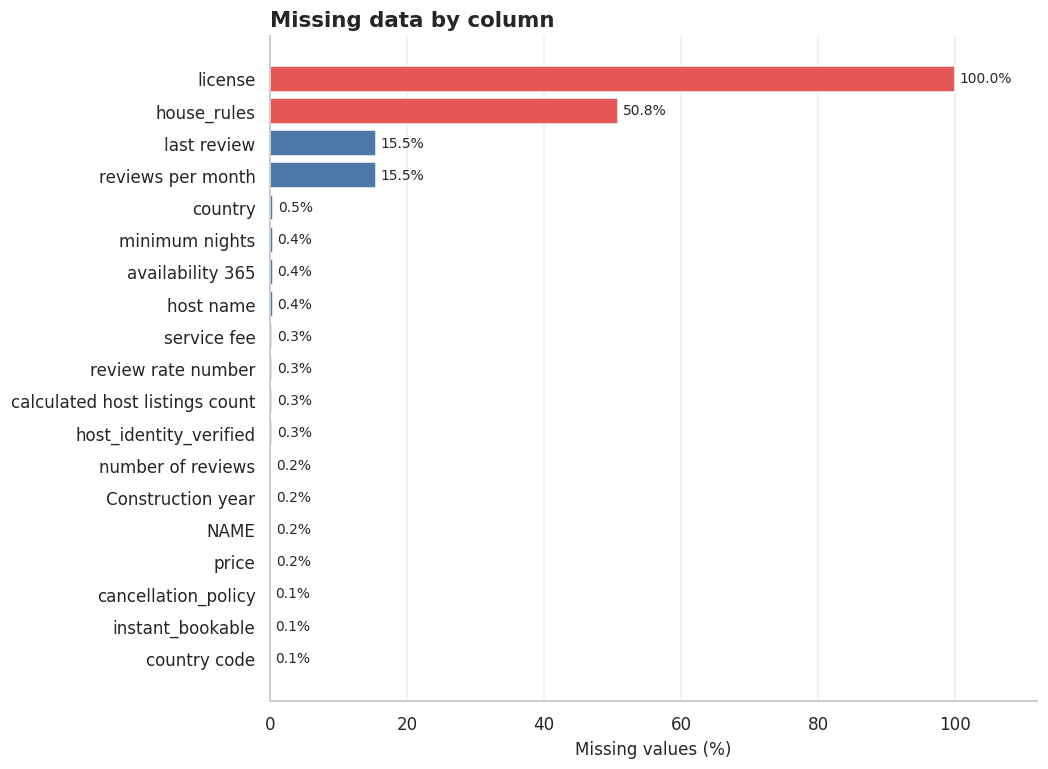

In [4]:
miss = audit.loc[audit["missing_pct"] > 0, "missing_pct"].sort_values()

fig, ax = plt.subplots(figsize=(9, 0.34 * len(miss) + 1.4))
bars = ax.barh(miss.index, miss.values, color=[WARN if v > 20 else ACCENT for v in miss.values])
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in miss.values], padding=3, fontsize=9)
ax.set(title="Missing data by column", xlabel="Missing values (%)", xlim=(0, miss.max() * 1.12))
ax.grid(axis="y", visible=False)
save_fig("01_missing_data")
plt.show()

Beyond missing values, a quick scan for duplicates, impossible values, and numbers stored as text.

The raw file has 541 exact duplicate rows and no repeated listing IDs after deduplication. There are also 48 rows where `minimum_nights` is outside 1–365, and 3,214 where `availability_365` falls outside its valid range. Five rows have a `last review` date after 2022 (2024, 2025, 2026, 2040 and 2058), which cannot be real: the latest genuine review in the file is from May 2022.

In [5]:
checks = pd.Series({
    "exact duplicate rows": raw.duplicated().sum(),
    "listing ids repeated (after removing exact duplicates)": raw.drop_duplicates()["id"].duplicated().sum(),
    "minimum nights < 1": (raw["minimum nights"] < 1).sum(),
    "minimum nights > 365": (raw["minimum nights"] > 365).sum(),
    "availability 365 outside 0-365": (~raw["availability 365"].dropna().between(0, 365)).sum(),
    "last review dates after 2022 (impossible)": (pd.to_datetime(raw["last review"], format="%m/%d/%Y", errors="coerce") > LAST_REVIEW_CUTOFF).sum(),
    "prices stored as text ('$' or ',')": raw["price"].astype("string").str.contains(r"[$,]", regex=True, na=False).sum(),
}, name="rows affected").astype(int)
checks.to_frame()

,rows affected
exact duplicate rows,541
listing ids repeated (after removing exact duplicates),0
minimum nights < 1,13
minimum nights > 365,35
availability 365 outside 0-365,3214
last review dates after 2022 (impossible),5
"prices stored as text ('$' or ',')",102352


## 3. Cleaning [Tutorial-based, improved]

Every step that drops rows is logged so the final row count is fully reproducible.

### 3.1 Tidy column names and remove duplicates

In [6]:
audit_log = []


def log_step(step, before, after, note=""):
    audit_log.append({"step": step, "rows_before": before, "rows_after": after,
                      "rows_removed": before - after, "note": note})


df = raw.copy()
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
df = df.rename(columns={"name": "listing_name",
                        "calculated_host_listings_count": "host_listings_count",
                        "review_rate_number": "review_rate"})

n = len(df)
df = df.drop_duplicates()
log_step("Remove exact duplicate rows", n, len(df))

n = len(df)
df = df.drop_duplicates(subset="id", keep="first")
log_step("Remove repeated listing ids", n, len(df), "keeps the first occurrence")

print("Columns:", list(df.columns))

Columns: ['id', 'listing_name', 'host_id', 'host_identity_verified', 'host_name', 'neighbourhood_group', 'neighbourhood', 'lat', 'long', 'country', 'country_code', 'instant_bookable', 'cancellation_policy', 'room_type', 'construction_year', 'price', 'service_fee', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'review_rate', 'host_listings_count', 'availability_365', 'house_rules', 'license']


### 3.2 Money and dates

In [7]:
def money_to_float(s):
    """'$1,092 ' -> 1092.0 (leaves numeric columns alone)."""
    if pd.api.types.is_numeric_dtype(s):
        return s.astype("float64")
    cleaned = s.astype("string").str.replace(r"[^0-9.\-]", "", regex=True)
    return pd.to_numeric(cleaned, errors="coerce").astype("float64")


def parse_us_dates(s):
    """Parse M/D/YYYY strings; if the file uses another format, let pandas infer it."""
    parsed = pd.to_datetime(s, format="%m/%d/%Y", errors="coerce")
    if parsed.notna().sum() < 0.5 * s.notna().sum():
        parsed = pd.to_datetime(s, errors="coerce")
    return parsed


df["price"] = money_to_float(df["price"])
df["service_fee"] = money_to_float(df["service_fee"])

raw_dates = df["last_review"]
df["last_review"] = parse_us_dates(raw_dates)
unparseable = int((raw_dates.notna() & df["last_review"].isna()).sum())
print(f"price and service_fee converted to float. Review dates that could not be parsed (set to missing): {unparseable}")

price and service_fee converted to float. Review dates that could not be parsed (set to missing): 0


### 3.3 Categorical columns

Borough names are standardised with fuzzy matching against the five real boroughs. Two rows had misspellings (`brookln`, `manhatan`) that were corrected automatically. Missing boroughs were recovered from the neighbourhood's most common borough — every neighbourhood maps cleanly to one borough with no conflicts.

In [8]:
def canonical_borough(x):
    if pd.isna(x):
        return np.nan
    key = str(x).strip().title()
    if key in BOROUGHS:
        return key
    match = difflib.get_close_matches(key, BOROUGHS, n=1, cutoff=0.6)
    return match[0] if match else np.nan


before = df["neighbourhood_group"]
after = before.map(canonical_borough)
changed = pd.DataFrame({"raw_value": before, "standardised": after})
changed = changed[changed["raw_value"].notna() & (changed["raw_value"] != changed["standardised"])]
df["neighbourhood_group"] = after

print("Borough spellings standardised:")
display(changed.value_counts(dropna=False).to_frame("rows") if len(changed) else "none found")

# a missing borough can be recovered from the neighbourhood (each neighbourhood belongs to one borough)
usual_borough = (df.dropna(subset=["neighbourhood_group", "neighbourhood"])
                   .groupby("neighbourhood")["neighbourhood_group"]
                   .agg(lambda s: s.mode().iat[0]))
n_missing = int(df["neighbourhood_group"].isna().sum())
df["neighbourhood_group"] = df["neighbourhood_group"].fillna(df["neighbourhood"].map(usual_borough))
print(f"Missing borough: {n_missing} -> {int(df['neighbourhood_group'].isna().sum())} (filled from the neighbourhood's usual borough)")

# consistency check: does any neighbourhood appear under more than one borough?
boroughs_per_nbhd = (df.dropna(subset=["neighbourhood", "neighbourhood_group"])
                       .groupby("neighbourhood")["neighbourhood_group"].nunique())
print(f"Neighbourhoods listed under more than one borough: {int((boroughs_per_nbhd > 1).sum())} of {len(boroughs_per_nbhd)}")

Borough spellings standardised:


,,rows
raw_value,standardised,
brookln,Brooklyn,1
manhatan,Manhattan,1


Missing borough: 29 -> 0 (filled from the neighbourhood's usual borough)


Neighbourhoods listed under more than one borough: 0 of 224


In [9]:
for col in ["host_identity_verified", "cancellation_policy"]:
    df[col] = df[col].astype("string").str.strip().str.lower().fillna("unknown")

df["instant_bookable"] = (df["instant_bookable"].astype("string").str.strip().str.lower()
                          .map({"true": "yes", "false": "no", "t": "yes", "f": "no", "1": "yes", "0": "no"})
                          .fillna("unknown"))
df["room_type"] = df["room_type"].astype("string").str.strip()
df["neighbourhood"] = df["neighbourhood"].astype("string").str.strip().fillna("unknown")

for col in ["host_identity_verified", "cancellation_policy", "instant_bookable", "room_type"]:
    print(f"{col:<24}", df[col].value_counts().to_dict())

host_identity_verified   {'unconfirmed': 50944, 'verified': 50825, 'unknown': 289}
cancellation_policy      {'moderate': 34162, 'strict': 33929, 'flexible': 33891, 'unknown': 76}
instant_bookable         {'no': 51186, 'yes': 50767, 'unknown': 105}
room_type                {'Entire home/apt': 53429, 'Private room': 46306, 'Shared room': 2208, 'Hotel room': 115}


### 3.4 Impossible values and reviews

Three decisions worth flagging:

- **Impossible values become missing, not zero.** A minimum stay of −1,223 nights is a data-entry error, not a real listing. 13 rows had `minimum_nights < 1`, 35 had it above 365, and 3,185 had `availability_365` outside 0–365 — all set to NaN.
- **Never-reviewed listings keep an empty `last_review`.** 15,832 listings (15.5%) were never reviewed. The tutorial fills those dates with the earliest date in the file, which invents a fake spike in the time chart (see §5.8). What is safe to fill is `reviews_per_month` and `number_of_reviews`: no reviews means zero.
- **Impossible review dates become missing too.** Five rows have a `last_review` in 2024, 2025, 2026, 2040 and 2058, while the latest genuine date is 21 May 2022. Left in, they stretch the time axis of the reviews chart out to 2060 and push every `days_since_last_review` value off by decades. Those listings were reviewed (they have review counts), so `has_reviews` is worked out before the dates are blanked.


In [10]:
bad_min = (df["minimum_nights"] < 1) | (df["minimum_nights"] > 365)
bad_avail = df["availability_365"].notna() & ~df["availability_365"].between(0, 365)
df.loc[bad_min, "minimum_nights"] = np.nan
df.loc[bad_avail, "availability_365"] = np.nan
print(f"minimum_nights outside 1-365 set to missing: {int(bad_min.sum())}  |  availability_365 outside 0-365 set to missing: {int(bad_avail.sum())}")

# Work out "never reviewed" BEFORE touching any dates, so it only means "no review was recorded".
no_reviews = df["last_review"].isna()
df.loc[no_reviews & df["reviews_per_month"].isna(), "reviews_per_month"] = 0
df.loc[no_reviews & df["number_of_reviews"].isna(), "number_of_reviews"] = 0
print(f"Listings that were never reviewed: {int(no_reviews.sum()):,} ({no_reviews.mean():.1%}). last_review stays missing for them.")

# A few rows carry review dates years in the future (up to 2058). Those listings were reviewed, but the date is wrong.
future_review = df["last_review"] > LAST_REVIEW_CUTOFF
future_years = sorted(df.loc[future_review, "last_review"].dt.year.tolist())
latest_valid = df.loc[~future_review, "last_review"].max()
df.loc[future_review, "last_review"] = pd.NaT
print(f"last_review dates after {LAST_REVIEW_CUTOFF:%Y-%m-%d} set to missing: {int(future_review.sum())} (years found: {future_years}). Latest date kept: {latest_valid:%Y-%m-%d}.")


minimum_nights outside 1-365 set to missing: 48  |  availability_365 outside 0-365 set to missing: 3185
Listings that were never reviewed: 15,832 (15.5%). last_review stays missing for them.
last_review dates after 2022-12-31 set to missing: 5 (years found: [2024, 2025, 2026, 2040, 2058]). Latest date kept: 2022-05-21.


### 3.5 Drop columns that carry no information, then summarise

`license` is 100% empty, `house_rules` is free text (a flag is kept in its place), and `country`/`country_code` hold a single value. After cleaning, the dataset goes from 102,599 to 102,058 rows — about 0.5% removed.

In [11]:
df["has_house_rules"] = df["house_rules"].notna().astype(int)     # keep this tiny signal before the free text is dropped
constant_cols = [c for c in ["country", "country_code"] if c in df.columns and df[c].nunique(dropna=True) <= 1]
drop_cols = ["license", "house_rules"] + constant_cols
df = df.drop(columns=drop_cols)

print("Dropped columns:", drop_cols)
print(f"  license is {raw['license'].isna().mean():.1%} empty, house_rules is free text, and {constant_cols} hold a single value.")
print(f"\nRaw: {len(raw):,} rows  ->  cleaned: {len(df):,} rows ({len(raw) - len(df):,} removed, {(len(raw) - len(df)) / len(raw):.2%})")

display(pd.DataFrame(audit_log))

still_missing = df.isna().sum()
still_missing = still_missing[still_missing > 0].sort_values(ascending=False).to_frame("still_missing")
still_missing["pct"] = (still_missing["still_missing"] / len(df) * 100).round(2)
print("\nStill missing after cleaning (handled inside the model pipelines later, not dropped):")
display(still_missing)

Dropped columns: ['license', 'house_rules', 'country', 'country_code']
  license is 100.0% empty, house_rules is free text, and ['country', 'country_code'] hold a single value.

Raw: 102,599 rows  ->  cleaned: 102,058 rows (541 removed, 0.53%)


,step,rows_before,rows_after,rows_removed,note
0,Remove exact duplicate rows,102599,102058,541,
1,Remove repeated listing ids,102058,102058,0,keeps the first occurrence



Still missing after cleaning (handled inside the model pipelines later, not dropped):


,still_missing,pct
last_review,15837,15.52
availability_365,3633,3.56
minimum_nights,448,0.44
host_name,404,0.40
review_rate,319,0.31
host_listings_count,319,0.31
service_fee,273,0.27
listing_name,250,0.24
price,247,0.24
construction_year,214,0.21


## 4. Feature engineering [Extension]

Four derived features used throughout sections 5–8:

- `dist_times_sq_km`: straight-line distance to Times Square (haversine) — a proxy for centrality
- `name_length`: character count of the listing title
- `has_reviews` / `days_since_last_review`: whether and how recently a listing was reviewed (counted back from the latest valid review, 21 May 2022)

In [12]:
TIMES_SQUARE = (40.7580, -73.9855)


def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0088                                   # mean Earth radius in km
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


df["dist_times_sq_km"] = haversine_km(df["lat"], df["long"], *TIMES_SQUARE)
df["name_length"] = df["listing_name"].astype("string").str.len().astype("float64")
df["has_reviews"] = (~no_reviews).astype(int)          # taken from before the impossible dates were blanked (section 3.4)
df["days_since_last_review"] = (df["last_review"].max() - df["last_review"]).dt.days.astype("float64")

df[["dist_times_sq_km", "name_length", "has_reviews", "days_since_last_review"]].describe().round(2)

,dist_times_sq_km,name_length,has_reviews,days_since_last_review
count,102050.00,101808.00,102058.00,86221.00
mean,7.38,37.58,0.84,1075.24
std,4.66,10.68,0.36,579.15
min,0.03,1.00,0.00,0.00
25%,3.95,31.00,1.00,1051.00
50%,6.72,39.00,1.00,1073.00
75%,9.66,47.00,1.00,1302.00
max,35.94,248.00,1.00,3601.00


## 5. Exploratory data analysis

### 5.1 Price distribution [Tutorial-based, redesigned]

Prices range from $50 to $1,200 (mean ≈ $625, median ≈ $625). The distribution is almost perfectly uniform — skewness is essentially zero and bin-to-bin variation is 0.03 — which strongly suggests the prices were generated synthetically rather than drawn from real listings. Real Airbnb prices are right-skewed, with many cheap options and a long expensive tail. Keep this in mind for the modelling section.

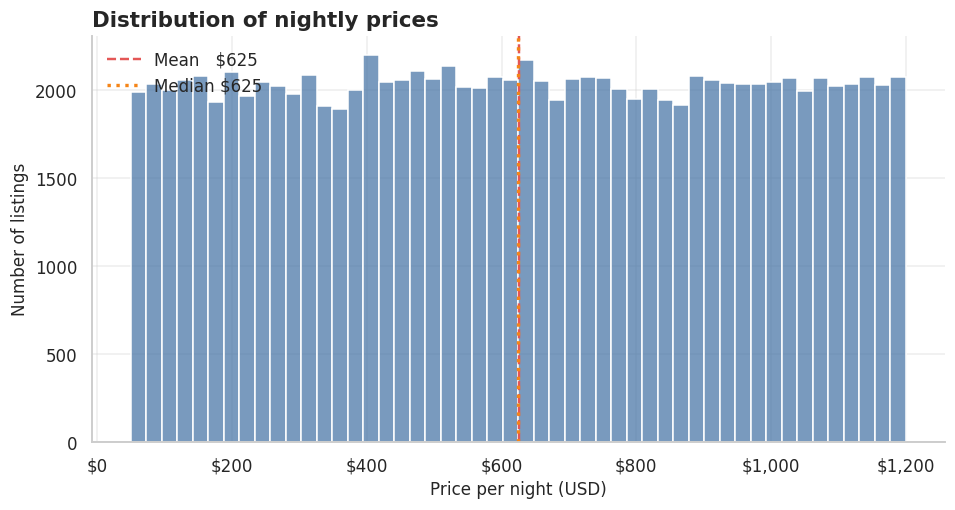

Range $50 to $1,200  |  skewness 0.00  |  bin-to-bin variation 0.03
Takeaway: the histogram is almost perfectly flat. Real listing prices are normally right-skewed (many cheap listings,
a long expensive tail), so this column looks synthetic. Keep that in mind for every price-related result below.


In [13]:
p = df["price"].dropna()

fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(p, bins=50, color=ACCENT, edgecolor="white", ax=ax)
ax.axvline(p.mean(), color=WARN, ls="--", lw=1.6, label=f"Mean   ${p.mean():,.0f}")
ax.axvline(p.median(), color="#F58518", ls=":", lw=2.2, label=f"Median ${p.median():,.0f}")
ax.set(title="Distribution of nightly prices", xlabel="Price per night (USD)", ylabel="Number of listings")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.legend()
save_fig("02_price_distribution")
plt.show()

counts, _ = np.histogram(p, bins=50)
flatness = counts.std() / counts.mean()          # ~0.02 for a perfectly flat histogram of this size
print(f"Range ${p.min():,.0f} to ${p.max():,.0f}  |  skewness {p.skew():.2f}  |  bin-to-bin variation {flatness:.2f}")
if flatness < 0.15:
    print("Takeaway: the histogram is almost perfectly flat. Real listing prices are normally right-skewed (many cheap listings,\n"
          "a long expensive tail), so this column looks synthetic. Keep that in mind for every price-related result below.")
else:
    print("Takeaway: the shape is uneven, which is what real listing prices usually look like.")

### 5.2 Service fee vs price [Extension]

The service fee is exactly 20% of the price for every listing (correlation = 1.0, ratio std ≈ 0.001). Including it as a feature would let any model "predict" price trivially — it's just arithmetic. `service_fee` is excluded from all models below.

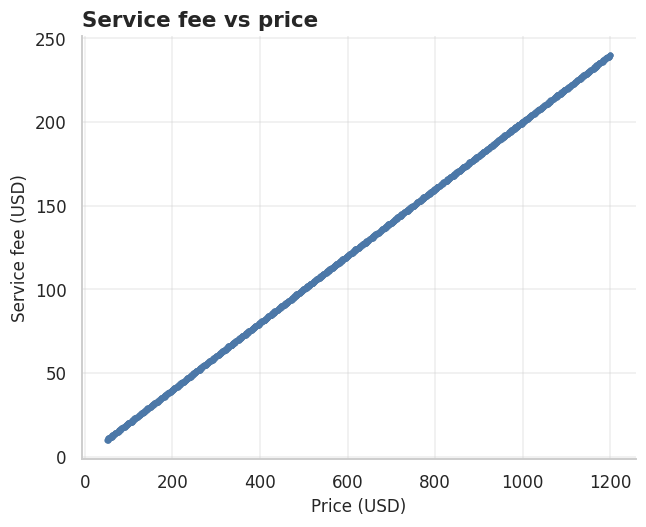

service_fee / price: min 0.192  median 0.200  max 0.208  |  correlation 1.0000
Takeaway: the fee is a fixed ~20% of the price, so it carries no independent information.


In [14]:
both = df.dropna(subset=["price", "service_fee"])
ratio = both["service_fee"] / both["price"]
sample = both.sample(min(4000, len(both)), random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(sample["price"], sample["service_fee"], s=8, alpha=0.5, color=ACCENT)
ax.set(title="Service fee vs price", xlabel="Price (USD)", ylabel="Service fee (USD)")
save_fig("03_service_fee_vs_price")
plt.show()

print(f"service_fee / price: min {ratio.min():.3f}  median {ratio.median():.3f}  max {ratio.max():.3f}  |  correlation {both['price'].corr(both['service_fee']):.4f}")
if ratio.std() < 0.01:
    print(f"Takeaway: the fee is a fixed ~{ratio.median():.0%} of the price, so it carries no independent information.")
else:
    print("Takeaway: the fee is related to price but not a fixed share of it.")

### 5.3 Room types and boroughs [Tutorial-based, redesigned]

Entire home/apt (52%) and Private room (45%) account for almost all listings. Shared rooms (2%) and Hotel rooms (<1%) are a small minority.

Manhattan and Brooklyn together hold ~83% of listings (43,571 and 41,644 respectively). Queens comes third at 13,199. The Bronx and Staten Island are a much smaller presence.

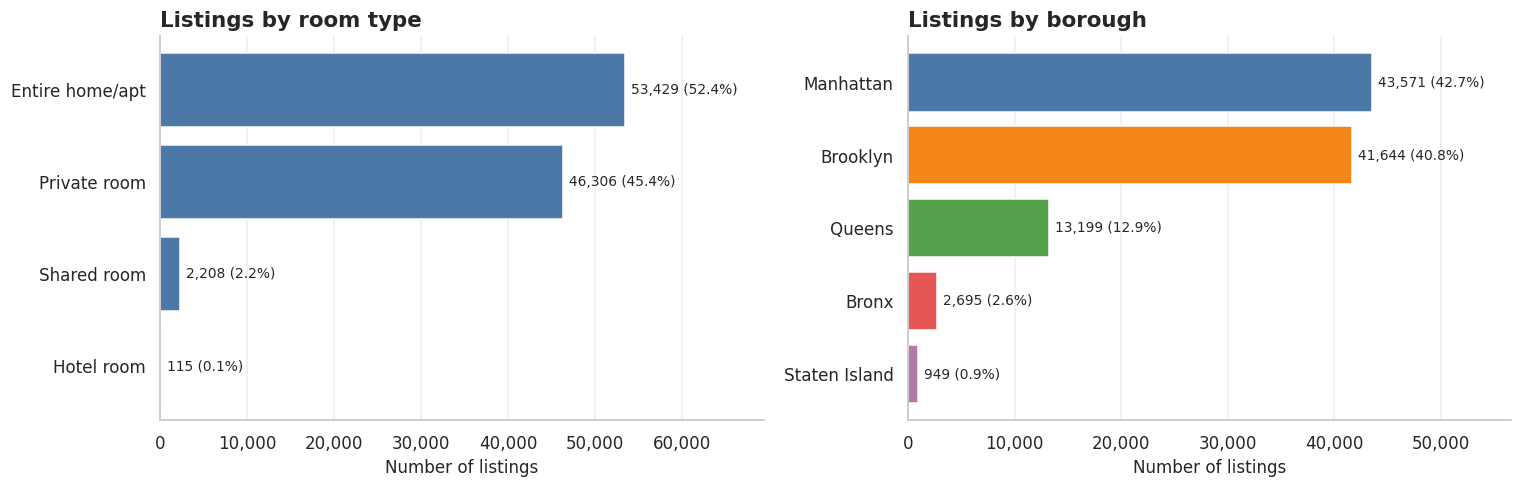

Takeaway: Manhattan and Brooklyn together hold 83% of listings; 'Entire home/apt' is the most common room type (52%).


In [15]:
room_counts = df["room_type"].value_counts()
borough_counts = df["neighbourhood_group"].value_counts()
borough_counts = borough_counts[borough_counts.index.isin(BOROUGHS)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

ax = axes[0]
bars = ax.barh(room_counts.index[::-1], room_counts.values[::-1], color=ACCENT)
ax.bar_label(bars, labels=[f"{v:,} ({v / room_counts.sum():.1%})" for v in room_counts.values[::-1]], padding=4, fontsize=9)
ax.set(title="Listings by room type", xlabel="Number of listings", xlim=(0, room_counts.max() * 1.3))
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="y", visible=False)

ax = axes[1]
bars = ax.barh(borough_counts.index[::-1], borough_counts.values[::-1],
               color=[BOROUGH_COLORS[b] for b in borough_counts.index[::-1]])
ax.bar_label(bars, labels=[f"{v:,} ({v / borough_counts.sum():.1%})" for v in borough_counts.values[::-1]], padding=4, fontsize=9)
ax.set(title="Listings by borough", xlabel="Number of listings", xlim=(0, borough_counts.max() * 1.3))
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="y", visible=False)

plt.tight_layout()
save_fig("04_room_type_and_borough")
plt.show()

top2 = borough_counts.iloc[:2]
print(f"Takeaway: {top2.index[0]} and {top2.index[1]} together hold {top2.sum() / borough_counts.sum():.0%} of listings; "
      f"'{room_counts.index[0]}' is the most common room type ({room_counts.iloc[0] / room_counts.sum():.0%}).")

### 5.4 Price by room type and borough [Tutorial-based, extended with a heatmap]

The heatmap starts its colour scale at zero — using only the data's own min-max range would make small differences look dramatic. Cells with fewer than 30 listings are left blank.

Because prices were synthetically generated, the spread across borough/room-type combinations is much smaller than you'd see in real data. The pattern exists but is muted.

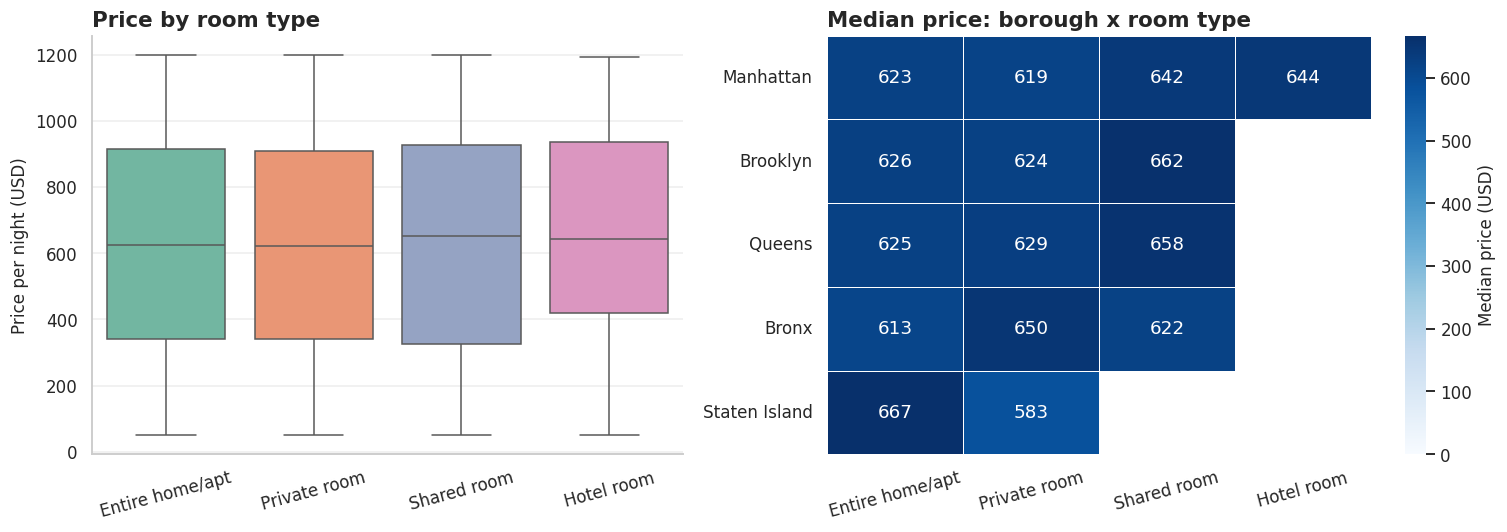

Takeaway: the highest and lowest median prices across all borough/room combinations differ by 13% of the overall median price.


In [16]:
room_order = df["room_type"].value_counts().index.tolist()
present = set(df["neighbourhood_group"].dropna())
borough_order = [b for b in BOROUGHS if b in present]

MIN_CELL = 30                                    # hide medians that rest on fewer listings than this
axes_spec = dict(index="neighbourhood_group", columns="room_type")
median_price = (df.pivot_table(values="price", aggfunc="median", **axes_spec)
                  .reindex(index=borough_order, columns=room_order))
cell_counts = (df.pivot_table(values="id", aggfunc="count", **axes_spec)
                 .reindex(index=borough_order, columns=room_order))
median_price = median_price.where(cell_counts >= MIN_CELL)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.15]})
sns.boxplot(data=df, x="room_type", y="price", hue="room_type", order=room_order, hue_order=room_order,
            palette="Set2", legend=False, fliersize=2, ax=axes[0])
axes[0].set(title="Price by room type", xlabel="", ylabel="Price per night (USD)")
axes[0].tick_params(axis="x", rotation=15)

sns.heatmap(median_price, annot=True, fmt=",.0f", cmap="Blues", vmin=0, linewidths=0.5,
            cbar_kws={"label": "Median price (USD)"}, ax=axes[1])
axes[1].set(title="Median price: borough x room type", xlabel="", ylabel="")
axes[1].grid(False)
axes[1].tick_params(axis="x", rotation=15)
plt.setp(axes[1].get_yticklabels(), rotation=0)
plt.tight_layout()
save_fig("05_price_by_room_and_borough")
plt.show()

spread = (median_price.max().max() - median_price.min().min()) / df["price"].median()
print(f"Takeaway: the highest and lowest median prices across all borough/room combinations differ by {spread:.0%} of the overall median price.")

### 5.5 Where the listings are [Extension]

The density map shows listings clustering heavily in lower Manhattan, Williamsburg, and Bushwick. The geographic spread matches what you'd expect for NYC, which is a useful sanity check — coordinates appear to be real even if prices aren't.

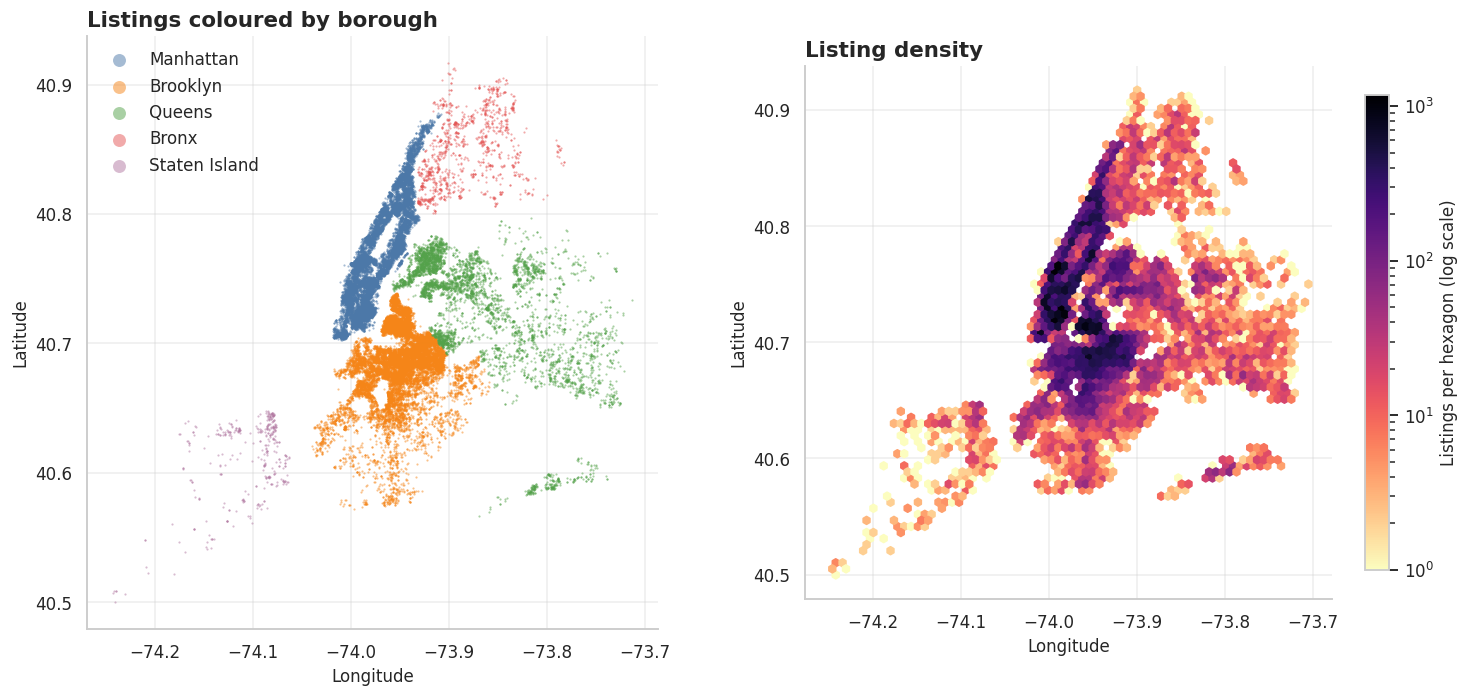

In [17]:
geo_all = df.dropna(subset=["lat", "long"])
geo_all = geo_all[geo_all["neighbourhood_group"].isin(BOROUGHS)]
geo_sample = geo_all.sample(min(40_000, len(geo_all)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for b in BOROUGHS:
    s = geo_sample[geo_sample["neighbourhood_group"] == b]
    axes[0].scatter(s["long"], s["lat"], s=2, alpha=0.5, color=BOROUGH_COLORS[b], label=b, linewidths=0)
axes[0].legend(markerscale=6, loc="upper left")
axes[0].set_title("Listings coloured by borough")

hb = axes[1].hexbin(geo_all["long"], geo_all["lat"], gridsize=70, bins="log", cmap="magma_r", mincnt=1)
fig.colorbar(hb, ax=axes[1], label="Listings per hexagon (log scale)", shrink=0.8)
axes[1].set_title("Listing density")

for ax in axes:
    ax.set_aspect(1 / np.cos(np.radians(40.72)))     # keeps north-south / east-west distances in proportion
    ax.set(xlabel="Longitude", ylabel="Latitude")
plt.tight_layout()
save_fig("06_listing_map")
plt.show()

### 5.6 Busiest neighbourhoods [Extension]

The top 15 neighbourhoods account for ~57% of all listings. Bedford-Stuyvesant (7,898) and Williamsburg (7,732) lead, followed by Harlem (5,441) and Bushwick (4,956). Manhattan neighbourhoods like Hell's Kitchen and the Upper West/East Sides round out the top 10.

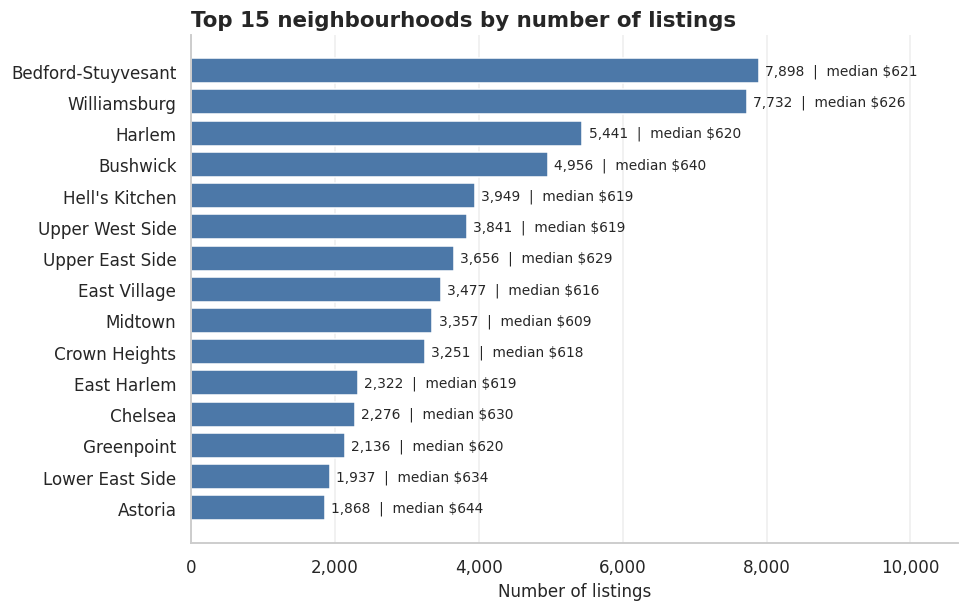

Takeaway: the 15 busiest of 225 neighbourhoods hold 57% of all listings.


In [18]:
top_nbhd = (df[df["neighbourhood"] != "unknown"]
            .groupby("neighbourhood")
            .agg(listings=("id", "size"), median_price=("price", "median"))
            .nlargest(15, "listings")
            .sort_values("listings"))

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top_nbhd.index, top_nbhd["listings"], color=ACCENT)
ax.bar_label(bars, labels=[f"{n:,}  |  median ${m:,.0f}" for n, m in zip(top_nbhd["listings"], top_nbhd["median_price"])],
             padding=4, fontsize=9)
ax.set(title="Top 15 neighbourhoods by number of listings", xlabel="Number of listings", xlim=(0, top_nbhd["listings"].max() * 1.35))
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="y", visible=False)
save_fig("07_top_neighbourhoods")
plt.show()

top15_share = top_nbhd["listings"].sum() / len(df)
print(f"Takeaway: the 15 busiest of {df['neighbourhood'].nunique()} neighbourhoods hold {top15_share:.0%} of all listings.")

### 5.7 Who runs the listings? [Extension]

`host_listings_count` shows how many listings each host manages. The split between single-listing hosts and multi-listing operators matters for understanding market concentration — professional operators tend to cluster in certain neighbourhoods and room types.

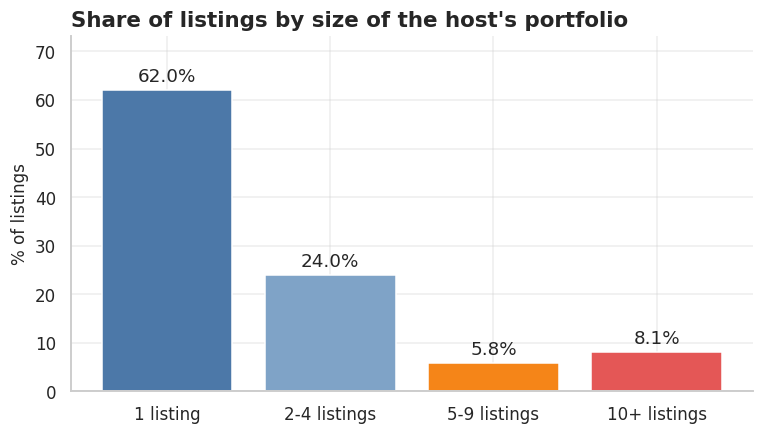

Takeaway: 14% of listings belong to hosts who manage 5 or more listings.


In [19]:
labels = ["1 listing", "2-4 listings", "5-9 listings", "10+ listings"]
host_group = pd.cut(df["host_listings_count"].dropna(), bins=[0, 1, 4, 9, np.inf], labels=labels)
share = host_group.value_counts(normalize=True).reindex(labels) * 100

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(labels, share.values, color=[ACCENT, "#7FA3C7", "#F58518", WARN])
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in share.values], padding=3)
ax.set(title="Share of listings by size of the host's portfolio", ylabel="% of listings", ylim=(0, share.max() * 1.18))
save_fig("08_host_concentration")
plt.show()

multi = share[["5-9 listings", "10+ listings"]].sum()
print(f"Takeaway: {multi:.0f}% of listings belong to hosts who manage 5 or more listings.")

### 5.8 Reviews over time [Tutorial-based, corrected]

The chart counts listings by the month of their most recent review, not actual review events. The left panel shows the tutorial's approach (filling missing dates with the earliest date in the file), which creates a huge artificial spike at the start. The right panel — leaving never-reviewed listings out — gives a cleaner picture of review activity over time. Five rows with impossible review dates (2024–2058) were blanked in §3.4; before that fix they stretched this axis out to 2060. About half of all last-review dates fall in 2019.

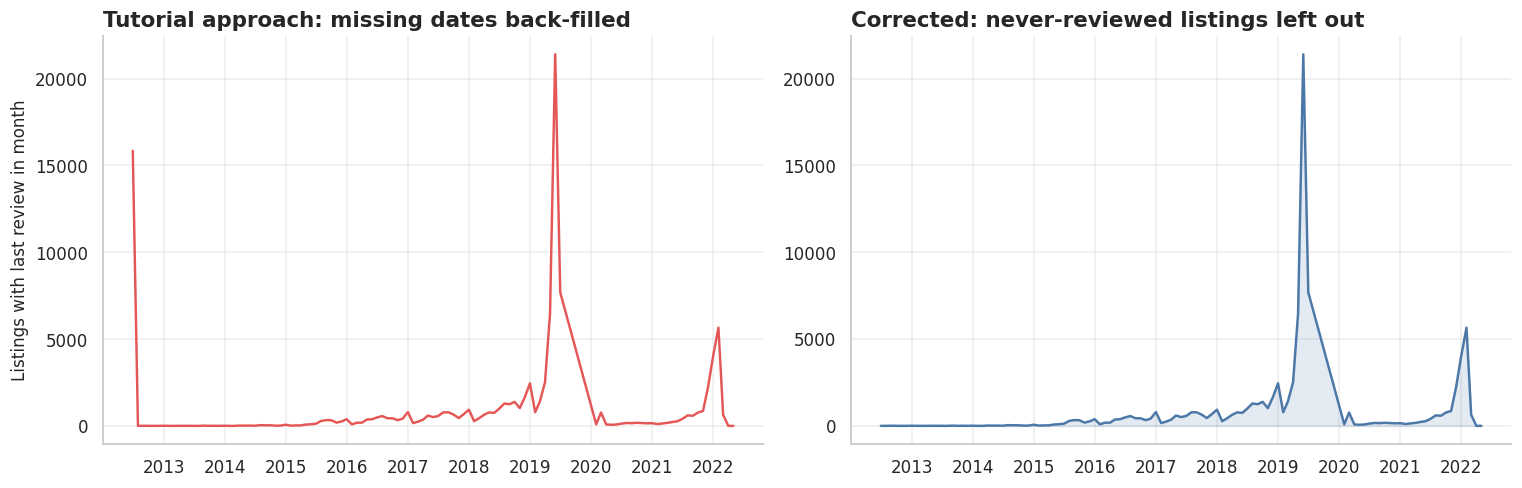

Back-filling puts all 15,837 missing dates onto Jul 2012, the earliest date in the file.
That month shows 15,839 listings, but only 2 actually had their last review then.
15,832 of the missing dates are listings that were never reviewed (15.5% of the data); the rest are the impossible dates blanked in section 3.4.


In [20]:
def monthly_counts(dates):
    m = dates.dropna().dt.to_period("M").value_counts().sort_index()
    m.index = m.index.to_timestamp()
    return m


backfilled = monthly_counts(df["last_review"].fillna(df["last_review"].min()))    # what the tutorial does
correct = monthly_counts(df["last_review"])                                       # never-reviewed listings left out

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharex=True)
axes[0].plot(backfilled.index, backfilled.values, color=WARN, lw=1.6)
axes[0].set(title="Tutorial approach: missing dates back-filled", ylabel="Listings with last review in month")
axes[1].plot(correct.index, correct.values, color=ACCENT, lw=1.6)
axes[1].fill_between(correct.index, correct.values, color=ACCENT, alpha=0.15)
axes[1].set(title="Corrected: never-reviewed listings left out")
plt.tight_layout()
save_fig("10_reviews_over_time_fix")
plt.show()

first_month = backfilled.index.min()
n_missing = int(df["last_review"].isna().sum())
print(f"Back-filling puts all {n_missing:,} missing dates onto {first_month:%b %Y}, the earliest date in the file.")
print(f"That month shows {backfilled.get(first_month, 0):,} listings, but only {correct.get(first_month, 0):,} actually had their last review then.")
print(f"{int(no_reviews.sum()):,} of the missing dates are listings that were never reviewed ({no_reviews.mean():.1%} of the data); the rest are the impossible dates blanked in section 3.4.")


### 5.9 Availability, minimum stay and review activity [Extension]

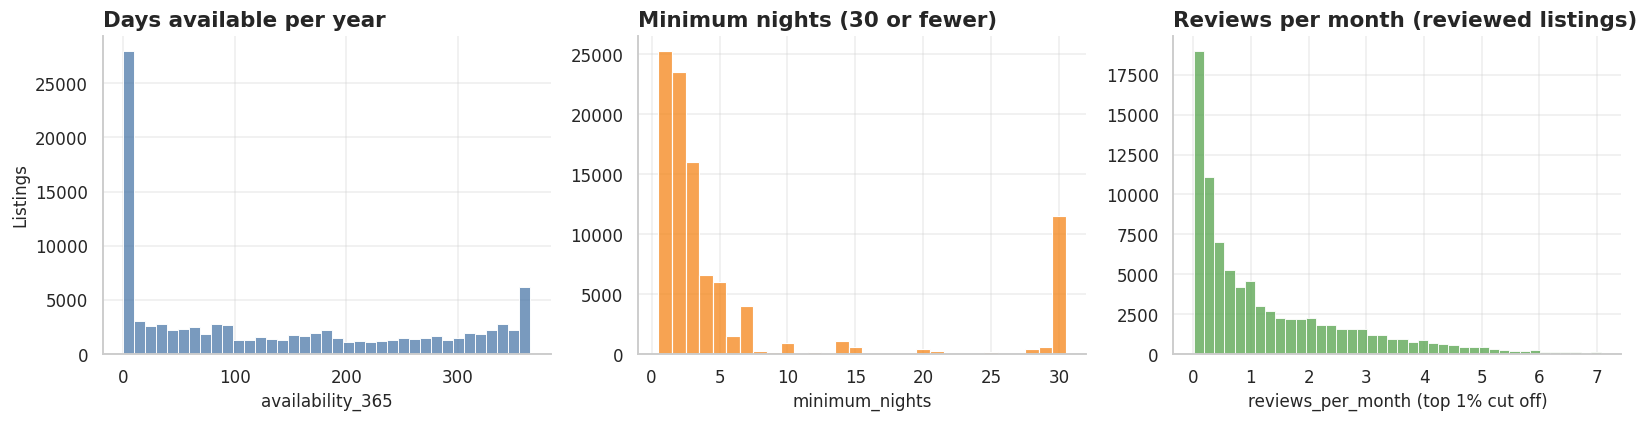

Takeaway: 1.6% of listings require more than 30 nights; median availability is 90 days per year.


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["availability_365"].dropna(), bins=37, color=ACCENT, edgecolor="white", ax=axes[0])
axes[0].set(title="Days available per year", xlabel="availability_365", ylabel="Listings")

min_nights = df["minimum_nights"].dropna()
sns.histplot(min_nights[min_nights <= 30], bins=np.arange(0.5, 31.5, 1), color="#F58518", edgecolor="white", ax=axes[1])
axes[1].set(title="Minimum nights (30 or fewer)", xlabel="minimum_nights", ylabel="")

rpm = df.loc[df["has_reviews"] == 1, "reviews_per_month"].dropna()
sns.histplot(rpm[rpm <= rpm.quantile(0.99)], bins=40, color="#54A24B", edgecolor="white", ax=axes[2])
axes[2].set(title="Reviews per month (reviewed listings)", xlabel="reviews_per_month (top 1% cut off)", ylabel="")

plt.tight_layout()
save_fig("11_availability_min_nights_reviews")
plt.show()

print(f"Takeaway: {(min_nights > 30).mean():.1%} of listings require more than 30 nights; "
      f"median availability is {df['availability_365'].median():.0f} days per year.")

### 5.10 Correlations [Extension]

Spearman (rank) correlation handles skewed columns and outliers better than Pearson, so it's used throughout. The strongest relationships are between `service_fee` and `price` (by design), and between review-related columns. Price itself correlates weakly with almost everything else — consistent with it being synthetically generated.

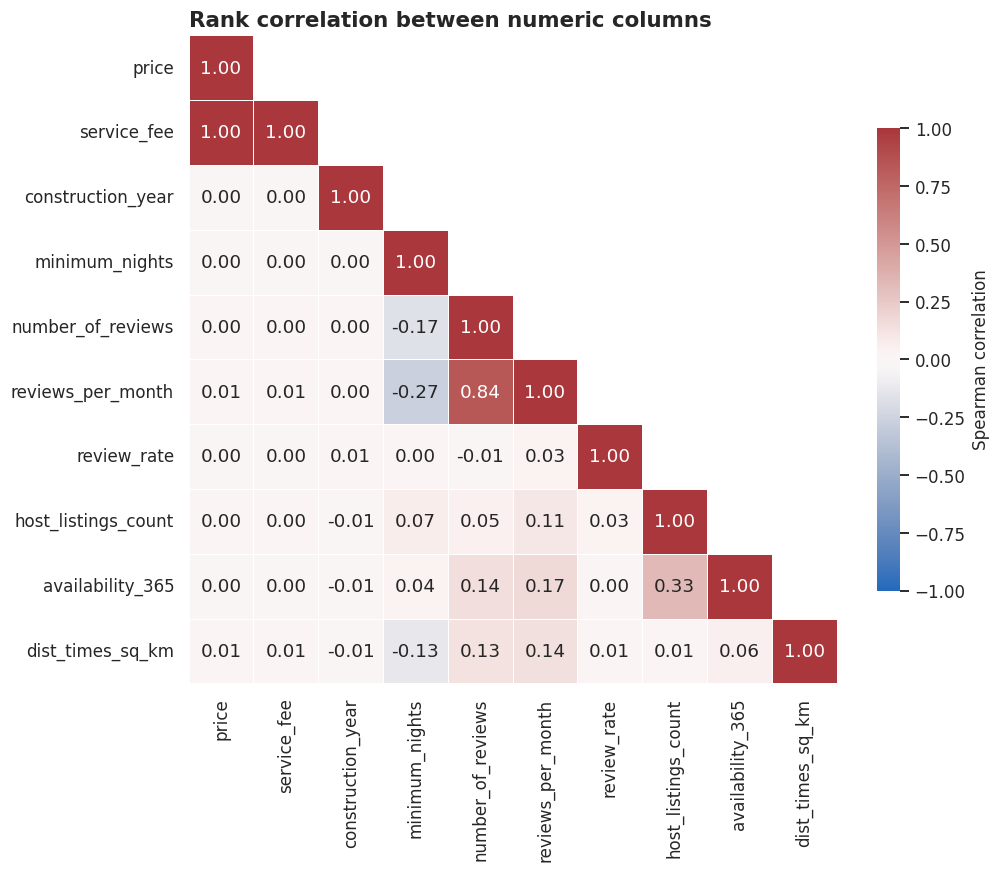

Strongest relationships:


,,spearman_rho
service_fee,price,1.000
reviews_per_month,number_of_reviews,0.843
availability_365,host_listings_count,0.328
reviews_per_month,minimum_nights,-0.267
availability_365,reviews_per_month,0.169
number_of_reviews,minimum_nights,-0.168


In [22]:
corr_cols = ["price", "service_fee", "construction_year", "minimum_nights", "number_of_reviews", "reviews_per_month",
             "review_rate", "host_listings_count", "availability_365", "dist_times_sq_km"]
corr = df[corr_cols].corr(method="spearman")
upper = np.triu(np.ones(corr.shape, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(9.5, 7.8))
sns.heatmap(corr, mask=upper, annot=corr.round(2) + 0.0, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.7, "label": "Spearman correlation"}, ax=ax)     # "+ 0.0" avoids printing -0.00
ax.set_title("Rank correlation between numeric columns")
ax.grid(False)
save_fig("12_correlation_heatmap")
plt.show()

pairs = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).stack()
print("Strongest relationships:")
display(pairs.sort_values(key=abs, ascending=False).head(6).round(3).to_frame("spearman_rho"))

### 5.11 Does price fall with distance from the centre? [Extension]

In real cities, it usually does. Here, Spearman correlation between distance to Times Square and price is essentially zero — another indicator that prices weren't generated from location. The median price is nearly flat across all distance bands.

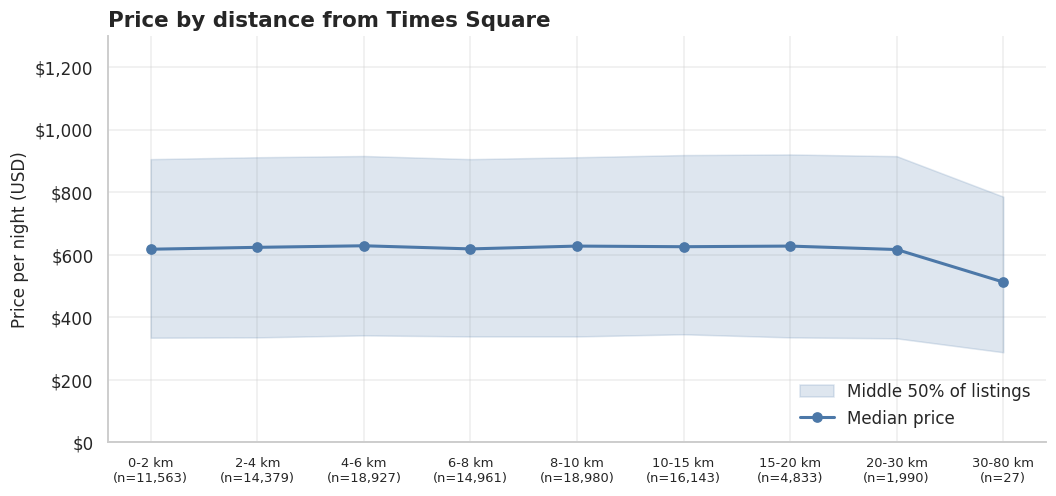

Spearman correlation between distance and price: 0.007 (p = 0.023)
Takeaway: essentially no relationship. In real Airbnb data, prices normally drop as you move away from the centre,
so this is another hint that price in this file was not generated from location.


In [23]:
d = df.dropna(subset=["price", "dist_times_sq_km"]).copy()
d["band"] = pd.cut(d["dist_times_sq_km"], bins=[0, 2, 4, 6, 8, 10, 15, 20, 30, 80])
by_band = d.groupby("band", observed=True)["price"].agg(
    median="median", q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75), n="size")
tick_labels = [f"{int(iv.left)}-{int(iv.right)} km\n(n={n:,})" for iv, n in zip(by_band.index, by_band["n"])]
x = np.arange(len(by_band))

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.fill_between(x, by_band["q1"], by_band["q3"], color=ACCENT, alpha=0.18, label="Middle 50% of listings")
ax.plot(x, by_band["median"], color=ACCENT, marker="o", lw=2, label="Median price")
ax.set_xticks(x)
ax.set_xticklabels(tick_labels, fontsize=8.5)
ax.set(title="Price by distance from Times Square", ylabel="Price per night (USD)", ylim=(0, max(1300, by_band["q3"].max() * 1.05)))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.legend(loc="lower right")
save_fig("13_price_vs_distance")
plt.show()

rho, pval = stats.spearmanr(d["dist_times_sq_km"], d["price"])
print(f"Spearman correlation between distance and price: {rho:.3f} (p {'< 0.001' if pval < 0.001 else f'= {pval:.3f}'})")
if abs(rho) < 0.05:
    print("Takeaway: essentially no relationship. In real Airbnb data, prices normally drop as you move away from the centre,\n"
          "so this is another hint that price in this file was not generated from location.")
else:
    print("Takeaway: price and distance are related, in the direction expected for a real city." if rho < 0
          else "Takeaway: price rises with distance from the centre, which is unusual for a city like New York.")

## 6. Does anything explain price? Statistical tests [Extension]

A Kruskal-Wallis test checks whether price differs across groups for each categorical column. With ~100k rows, even tiny differences usually show up as statistically significant, so the table also reports **epsilon-squared** — how much of the price variation the grouping actually explains.

Rough guide: below 0.01 = negligible, 0.01–0.06 = small, 0.06–0.14 = medium, above 0.14 = large.

None of the factors is significant once the Bonferroni correction is applied. The p-values for the categorical columns run from 0.17 to 0.96, and `construction_year` (p = 0.015) does not survive the correction. `construction_year` has the largest epsilon-squared, but at 0.0003 it is negligible. The conclusion going into Section 7: don't expect any model to predict price well.


In [24]:
def kruskal_effect(data, group_col, value_col="price", min_group=30):
    groups = [g[value_col].dropna().to_numpy() for _, g in data.groupby(group_col)
              if g[value_col].notna().sum() >= min_group]
    H, p_value = stats.kruskal(*groups)
    n_total = sum(len(g) for g in groups)
    return {"factor": group_col, "groups": len(groups), "H": H, "p_value": p_value, "epsilon_sq": H / (n_total - 1)}


def effect_label(e):
    return "negligible" if e < 0.01 else "small" if e < 0.06 else "medium" if e < 0.14 else "large"


factors = ["room_type", "neighbourhood_group", "cancellation_policy", "host_identity_verified", "instant_bookable", "construction_year"]
tests = pd.DataFrame([kruskal_effect(df, f) for f in factors]).set_index("factor")
tests["effect_size"] = tests["epsilon_sq"].map(effect_label)
tests["significant_at_bonferroni_0.05"] = tests["p_value"] < 0.05 / len(factors)   # corrects for running 6 tests
tests["H"] = tests["H"].round(2)
tests["epsilon_sq"] = tests["epsilon_sq"].round(5)
tests["p_value"] = tests["p_value"].map(lambda v: "<1e-300" if v < 1e-300 else f"{v:.3g}")
tests

,groups,H,p_value,epsilon_sq,effect_size,significant_at_bonferroni_0.05
factor,,,,,,
room_type,4,3.65,0.302,0.00004,negligible,False
neighbourhood_group,5,6.35,0.174,0.00006,negligible,False
cancellation_policy,4,0.67,0.88,0.00001,negligible,False
host_identity_verified,3,2.65,0.266,0.00003,negligible,False
instant_bookable,3,0.09,0.956,0.00000,negligible,False
construction_year,20,34.76,0.0149,0.00034,negligible,False


In [25]:
biggest = tests["epsilon_sq"].astype(float).idxmax()
print(f"Largest effect: {biggest} (epsilon-squared = {float(tests.loc[biggest, 'epsilon_sq']):.5f}, {tests.loc[biggest, 'effect_size']}).")
if (tests["effect_size"] == "negligible").all():
    print("Takeaway: none of the categorical columns explains price in any meaningful way. Expect models to struggle in section 7.")
else:
    print("Takeaway: at least one column shows a practical effect on price, so a model may find some signal.")

Largest effect: construction_year (epsilon-squared = 0.00034, negligible).
Takeaway: none of the categorical columns explains price in any meaningful way. Expect models to struggle in section 7.


## 7. Modeling: can we predict price? [Extension]

**Goal:** predict nightly price from listing attributes (regression).

A model is only useful if it beats the naive baseline of always predicting the average price. R² = 0 means no improvement over that; MAE gives the typical error in dollars.

### 7.1 A leakage check first

`service_fee` is a fixed 20% of price, so a model that sees it achieves R² ≈ 1.0 — impressive-looking, completely meaningless. It's excluded from all models that follow.

In [26]:
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             mean_absolute_error, mean_squared_error, r2_score)
import sklearn

print("scikit-learn", sklearn.__version__)

m = df.dropna(subset=["price", "service_fee"])
leaky = LinearRegression().fit(m[["service_fee"]], m["price"])
leak_r2 = r2_score(m["price"], leaky.predict(m[["service_fee"]]))
print(f"R² of a model that only sees service_fee: {leak_r2:.4f}")
if leak_r2 > 0.99:
    print("This is arithmetic, not prediction (fee = a fixed share of price). service_fee is excluded from all models below.")

scikit-learn 1.8.0
R² of a model that only sees service_fee: 1.0000
This is arithmetic, not prediction (fee = a fixed share of price). service_fee is excluded from all models below.


### 7.2 Features and train/test split

Numeric features are imputed with the median; categoricals are one-hot encoded for the linear model and ordinal encoded for tree models. Neighbourhoods with fewer than 50 listings are grouped into "Other". 20% of the data is held out as a test set — it's never touched during training or model selection.

In [27]:
NUM_FEATURES = ["lat", "long", "dist_times_sq_km", "construction_year", "minimum_nights", "number_of_reviews",
                "reviews_per_month", "review_rate", "host_listings_count", "availability_365",
                "days_since_last_review", "name_length", "has_reviews", "has_house_rules"]
CAT_FEATURES = ["neighbourhood_group", "neighbourhood", "room_type", "cancellation_policy",
                "host_identity_verified", "instant_bookable"]

model_df = df.dropna(subset=["price"]).copy()
nbhd_counts = model_df["neighbourhood"].value_counts()
rare = nbhd_counts[nbhd_counts < 50].index
model_df["neighbourhood"] = model_df["neighbourhood"].where(~model_df["neighbourhood"].isin(rare), "Other")
print(f"{len(rare)} rare neighbourhoods grouped into 'Other' -> {model_df['neighbourhood'].nunique()} neighbourhood levels")

X = model_df[NUM_FEATURES + CAT_FEATURES].copy()
for c in CAT_FEATURES:
    X[c] = X[c].astype(object)
y = model_df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train {len(X_train):,} rows | Test {len(X_test):,} rows | {len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical features")

93 rare neighbourhoods grouped into 'Other' -> 133 neighbourhood levels
Train 81,448 rows | Test 20,363 rows | 14 numeric + 6 categorical features


### 7.3 Models and cross-validation

Four models, evaluated with 5-fold cross-validation on the training set and then confirmed on the held-out test set:

1. **Baseline** — always predicts the mean price
2. **Ridge regression** — a regularised linear model
3. **Random forest** — 120 trees averaged together
4. **Gradient boosting (HistGB)** — trees built sequentially, each correcting the previous one

In [28]:
numeric_linear = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
pre_linear = ColumnTransformer([
    ("num", numeric_linear, NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
])
pre_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUM_FEATURES),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_FEATURES),
])
cat_mask = [False] * len(NUM_FEATURES) + [True] * len(CAT_FEATURES)     # tells HistGB which columns are categorical

models = {
    "Baseline (predict the mean)": Pipeline([("prep", pre_linear), ("model", DummyRegressor(strategy="mean"))]),
    "Ridge regression": Pipeline([("prep", pre_linear), ("model", Ridge(alpha=10.0))]),
    "Random forest": Pipeline([("prep", pre_tree), ("model", RandomForestRegressor(
        n_estimators=120, min_samples_leaf=25, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient boosting (HistGB)": Pipeline([("prep", pre_tree), ("model", HistGradientBoostingRegressor(
        categorical_features=cat_mask, learning_rate=0.06, max_iter=300, early_stopping=True, random_state=RANDOM_STATE))]),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in models.items():
    t0 = time.perf_counter()
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring={"r2": "r2", "mae": "neg_mean_absolute_error"})
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({
        "model": name,
        "cv_r2_mean": scores["test_r2"].mean(), "cv_r2_std": scores["test_r2"].std(),
        "cv_mae_mean": -scores["test_mae"].mean(),
        "test_r2": r2_score(y_test, pred),
        "test_mae": mean_absolute_error(y_test, pred),
        "test_rmse": float(np.sqrt(mean_squared_error(y_test, pred))),
    })
    print(f"{name:<30} finished in {time.perf_counter() - t0:5.0f}s")

results = pd.DataFrame(rows).set_index("model")
results.round(4)

Baseline (predict the mean)    finished in     1s


Ridge regression               finished in     3s


Random forest                  finished in   253s


Gradient boosting (HistGB)     finished in    13s


,cv_r2_mean,cv_r2_std,cv_mae_mean,test_r2,test_mae,test_rmse
model,,,,,,
Baseline (predict the mean),-0.0001,0.0001,286.7903,-0.0000,287.1418,331.6304
Ridge regression,-0.0013,0.0008,286.8848,-0.0008,287.1185,331.7671
Random forest,0.0610,0.0016,277.0644,0.0802,274.3898,318.0573
Gradient boosting (HistGB),0.0249,0.0065,282.3208,0.0376,280.6470,325.3436


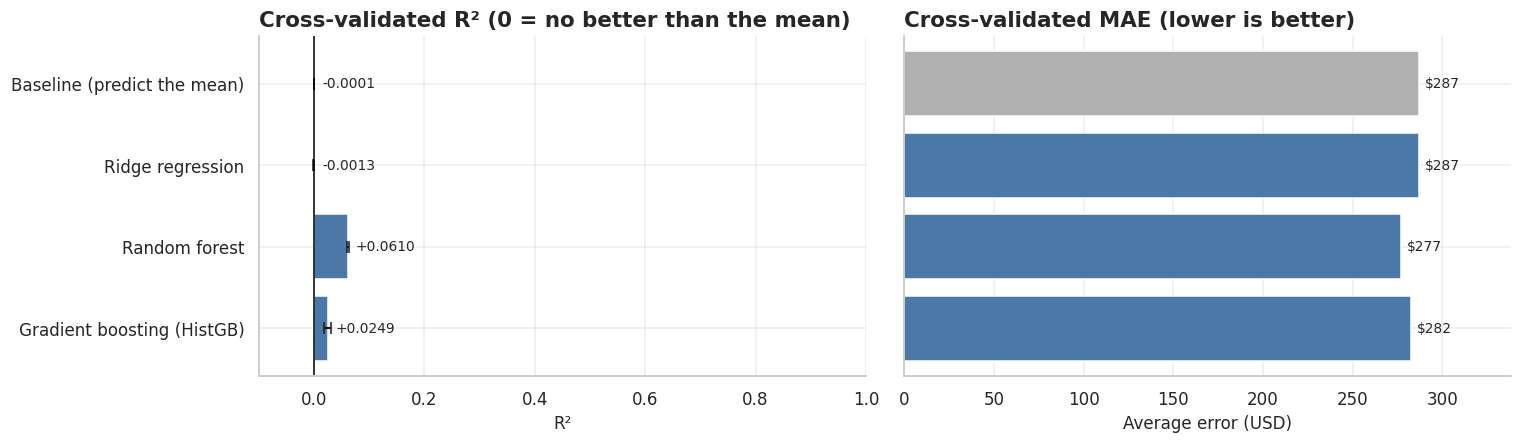

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
names = results.index[::-1]

r2 = results["cv_r2_mean"][::-1]
axes[0].barh(names, r2.values, xerr=results["cv_r2_std"][::-1].values, color=ACCENT, capsize=4)
axes[0].axvline(0, color="black", lw=1)
for yi, v in enumerate(r2.values):                  # print the numbers: near-zero bars are otherwise invisible
    axes[0].text(max(v, 0) + 0.015, yi, f"{v:+.4f}", va="center", fontsize=9)
axes[0].set(title="Cross-validated R² (0 = no better than the mean)", xlabel="R²",
            xlim=(min(-0.1, r2.min() - 0.03), 1))

mae = results["cv_mae_mean"][::-1]
bars = axes[1].barh(names, mae.values, color=[GREY if n.startswith("Baseline") else ACCENT for n in names])
axes[1].bar_label(bars, labels=[f"${v:,.0f}" for v in mae.values], padding=4, fontsize=9)
axes[1].set(title="Cross-validated MAE (lower is better)", xlabel="Average error (USD)", xlim=(0, mae.max() * 1.18))

plt.tight_layout()
save_fig("14_model_comparison")
plt.show()

### 7.4 The verdict

No model gets anywhere near explaining price. Ridge regression is no better than always guessing the average. The random forest is the best by cross-validation, but it explains only about 6–8% of the variance (R² ≈ 0.06 in cross-validation, 0.08 on the held-out test set) and cuts the typical error by roughly $13, about 4%, compared with the baseline. Gradient boosting lands in between.

That is a weak signal rather than none, and it is small enough that I would not read anything into which features produce it. I did not trace where it comes from. Because flexible models find so little, the problem is the data, not the algorithm: price in this dataset appears not to have been generated from the available features, so more tuning would mostly fit noise.


In [30]:
candidates = results.loc[~results.index.str.startswith("Baseline")]
best_name = candidates["cv_r2_mean"].idxmax()
base = results.loc[results.index.str.startswith("Baseline")].iloc[0]
best = results.loc[best_name]
mae_gain = (base["test_mae"] - best["test_mae"]) / base["test_mae"]

print(f"Best model by cross-validation: {best_name}")
print(f"  Test R²  : {best['test_r2']:.4f}   (baseline {base['test_r2']:.4f})")
print(f"  Test MAE : ${best['test_mae']:,.0f}   (baseline ${base['test_mae']:,.0f}; improvement over baseline {mae_gain:+.2%})")

if best["test_r2"] < 0.05:
    print("\nVerdict: NO practical predictive signal. None of the models beats 'always guess the average price' by a meaningful margin.")
    print("When flexible models find nothing, the cause is usually the data (price is not driven by these features), not the algorithm,")
    print("so more tuning or a bigger model would mostly fit noise.")
elif best["test_r2"] < 0.3:
    print("\nVerdict: WEAK signal. The model beats the baseline, but most of the price variation stays unexplained.")
else:
    print("\nVerdict: The features carry real signal for price. The model clearly beats the baseline.")

Best model by cross-validation: Random forest
  Test R²  : 0.0802   (baseline -0.0000)
  Test MAE : $274   (baseline $287; improvement over baseline +4.44%)

Verdict: WEAK signal. The model beats the baseline, but most of the price variation stays unexplained.


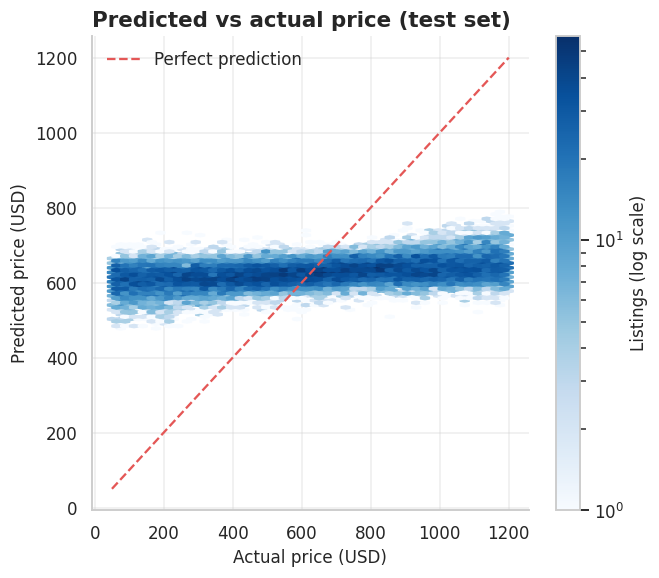

Model shown: Random forest.


In [31]:
best_model = models[best_name]
best_pred = best_model.predict(X_test)

fig, ax = plt.subplots(figsize=(6.4, 5.6))
hb = ax.hexbin(y_test, best_pred, gridsize=45, bins="log", cmap="Blues", mincnt=1)
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
ax.plot(lims, lims, color=WARN, ls="--", lw=1.5, label="Perfect prediction")
ax.set(title="Predicted vs actual price (test set)", xlabel="Actual price (USD)", ylabel="Predicted price (USD)")
fig.colorbar(hb, label="Listings (log scale)")
ax.legend(loc="upper left")
save_fig("15_predicted_vs_actual")
plt.show()
print(f"Model shown: {best_name}.")
if best["test_r2"] < 0.05:
    print("The predictions collapse into a narrow horizontal band near the average price: the model cannot tell listings apart.")

### 7.5 Which features matter? Permutation importance

Each feature is shuffled on the test set; the drop in R² shows how much the model relied on it. Bars at or near zero mean the model gained essentially nothing from that feature. The axis spans at least 0.05 so noise-level bars aren't blown up to look important.

Read this chart with care, because the model behind it is weak (test R² ≈ 0.08). The importances are small, spread over about 14 features, and no feature clearly stands out. Longitude and latitude are at the top, but §5.11 found no relationship between location and price, so this does not show that location drives price. It shows which inputs the random forest leaned on, not that they cause anything.


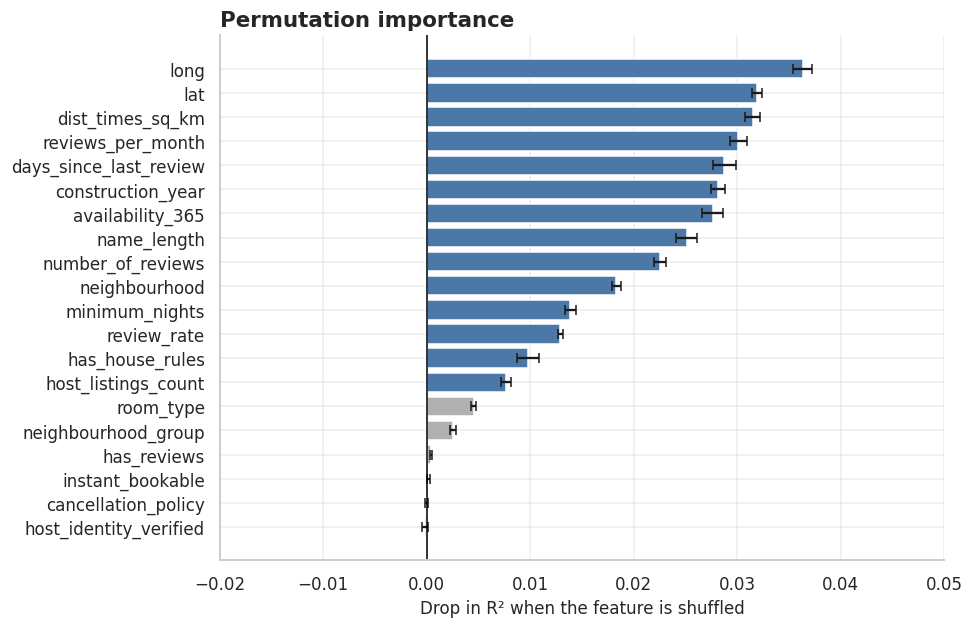

Most influential feature: long (drop in R² = 0.0363).
Features that contribute more than 0.005 R²: 14 of 20.


In [32]:
sample_idx = X_test.sample(min(5000, len(X_test)), random_state=RANDOM_STATE).index
perm = permutation_importance(best_model, X_test.loc[sample_idx], y_test.loc[sample_idx],
                              n_repeats=5, random_state=RANDOM_STATE, scoring="r2", n_jobs=1)
imp = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std})
         .sort_values("importance"))

fig, ax = plt.subplots(figsize=(8.5, 6.2))
ax.barh(imp["feature"], imp["importance"], xerr=imp["std"], capsize=3,
        color=[ACCENT if v > 0.005 else GREY for v in imp["importance"]])
ax.axvline(0, color="black", lw=1)
lim = max(0.05, imp["importance"].max() * 1.3)      # axis spans at least 0.05 so noise-level bars are not blown up
ax.set(title="Permutation importance", xlabel="Drop in R² when the feature is shuffled", xlim=(-lim * 0.4, lim))
save_fig("16_permutation_importance")
plt.show()

top = imp.iloc[-1]
print(f"Most influential feature: {top['feature']} (drop in R² = {top['importance']:.4f}).")
print(f"Features that contribute more than 0.005 R²: {int((imp['importance'] > 0.005).sum())} of {len(imp)}.")

## 8. Modeling: predicting borough from coordinates [Extension]

A second modelling task where the features *should* work: classify a listing's borough from latitude and longitude alone. This is closer to a sanity check than a finding, because a borough is a geographic area and coordinates are expected to recover it.

This also doubles as a data-quality check. Predictions are made out-of-fold (each row is scored by a model that never saw it), so listings where the model strongly disagrees with the recorded borough are worth a manual look.

In [33]:
geo = df[df["neighbourhood_group"].isin(BOROUGHS)].dropna(subset=["lat", "long"]).reset_index(drop=True)
Xg = geo[["lat", "long"]].to_numpy()
yg = geo["neighbourhood_group"].to_numpy(dtype=object)

rf_geo = RandomForestClassifier(n_estimators=150, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
proba = cross_val_predict(rf_geo, Xg, yg, cv=skf, method="predict_proba")

classes = np.array(sorted(set(yg)))
pred_geo = classes[proba.argmax(axis=1)]

acc = accuracy_score(yg, pred_geo)
majority = pd.Series(yg).value_counts(normalize=True).iloc[0]
macro_f1 = f1_score(yg, pred_geo, average="macro")
print(f"Out-of-fold accuracy: {acc:.1%}  |  'always guess the biggest borough' baseline: {majority:.1%}  |  macro F1: {macro_f1:.3f}")

report = pd.DataFrame(classification_report(yg, pred_geo, output_dict=True)).T.round(3)
display(report.loc[list(classes) + ["macro avg"], ["precision", "recall", "f1-score", "support"]])

Out-of-fold accuracy: 100.0%  |  'always guess the biggest borough' baseline: 42.7%  |  macro F1: 0.999


,precision,recall,f1-score,support
Bronx,0.999,0.998,0.999,2695.0
Brooklyn,1.000,1.000,1.000,41641.0
Manhattan,1.000,1.000,1.000,43567.0
Queens,0.999,0.999,0.999,13198.0
Staten Island,1.000,1.000,1.000,949.0
macro avg,0.999,0.999,0.999,102050.0


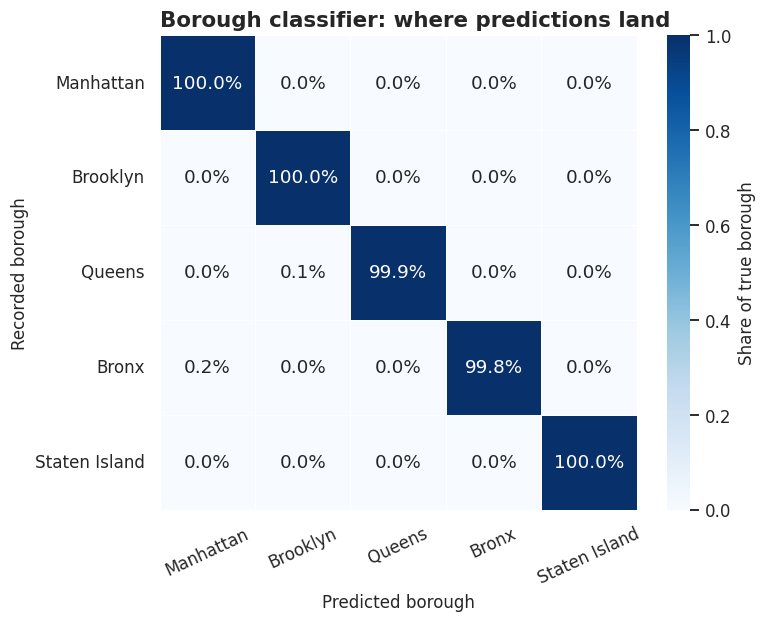

Takeaway: coordinates alone recover the borough far better than guessing, so location is genuinely informative here.


In [34]:
order = [b for b in BOROUGHS if b in classes]
cm = confusion_matrix(yg, pred_geo, labels=order, normalize="true")

fig, ax = plt.subplots(figsize=(7, 5.6))
sns.heatmap(cm, annot=True, fmt=".1%", cmap="Blues", vmin=0, vmax=1, linewidths=0.5, xticklabels=order, yticklabels=order,
            cbar_kws={"label": "Share of true borough"}, ax=ax)
ax.set(title="Borough classifier: where predictions land", xlabel="Predicted borough", ylabel="Recorded borough")
ax.tick_params(axis="x", rotation=25)
plt.setp(ax.get_yticklabels(), rotation=0)
ax.grid(False)
save_fig("17_borough_confusion")
plt.show()

if acc - majority > 0.10:
    print("Takeaway: coordinates alone recover the borough far better than guessing, so location is genuinely informative here.")
    if best["test_r2"] < 0.05:
        print("That is in sharp contrast to price in section 7, where no model beat the baseline.")
else:
    print("Takeaway: coordinates add little beyond guessing the biggest borough, which suggests the coordinates or labels are unreliable.")

### 8.1 Listings whose borough label looks suspicious

A listing is flagged when the out-of-fold model gives its recorded borough less than 2% probability. That doesn't prove the label is wrong — border listings are genuinely ambiguous — but these are the best candidates for review. In this run no listing is flagged, so there is nothing to review and no map is drawn; the code below draws one if a future run flags any.

In [35]:
recorded_idx = np.searchsorted(classes, yg)
geo["p_recorded"] = proba[np.arange(len(yg)), recorded_idx]
geo["model_says"] = pred_geo
suspects = geo[geo["p_recorded"] < 0.02].sort_values("p_recorded")

print(f"{len(suspects):,} of {len(geo):,} listings ({len(suspects) / len(geo):.2%}) have a recorded borough the model finds very unlikely.")
if len(suspects):
    display(suspects[["id", "neighbourhood", "neighbourhood_group", "model_says", "p_recorded", "lat", "long"]].head(10).round(4))

    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    ax.scatter(geo["long"], geo["lat"], s=1, color="#D9D9D9", alpha=0.5, linewidths=0)
    ax.scatter(suspects["long"], suspects["lat"], s=28, color=WARN, marker="x", linewidths=1.2,
               label=f"{len(suspects):,} suspicious borough labels")
    ax.set_aspect(1 / np.cos(np.radians(40.72)))
    ax.set(title="Where the suspicious labels are", xlabel="Longitude", ylabel="Latitude")
    ax.legend(loc="upper left")
    save_fig("18_suspicious_borough_labels")
    plt.show()

0 of 102,050 listings (0.00%) have a recorded borough the model finds very unlikely.


## 9. Conclusions

Key findings from this analysis:

1. **Data quality:** 102,599 raw rows → 102,058 after cleaning (0.53% removed). 541 exact duplicates dropped. 15,832 listings (15.5%) were never reviewed, and 5 impossible review dates (2024–2058) were set to missing.
2. **Price looks synthetic:** the distribution is almost perfectly uniform ($50–$1,200, mean ≈ $625), skewness ≈ 0, and price shows no practically meaningful relationship with location, room type, or any other feature.
3. **Service fee leakage:** `service_fee` is exactly 20% of `price` (R² = 1.0000 if used as a feature) and is excluded from all models.
4. **Price is barely predictable:** the best model (random forest) reaches a test R² of about 0.08 and a mean absolute error of $274 against $287 for always guessing the average, roughly 4% better. This is a data problem, not a modelling one.
5. **Borough classification works, as expected:** coordinates alone classify borough with ~100% accuracy against a 42.7% majority-class baseline, and no borough label is flagged as suspicious. A borough is a geographic area, so this mainly confirms the coordinates are reliable. Location is informative about borough; price just wasn't generated from it.


In [36]:
price_clean = df["price"].dropna()
summary = [
    "KEY FINDINGS",
    "",
    f"1. Data     : {len(raw):,} raw rows -> {len(df):,} after cleaning; {int(no_reviews.sum()):,} listings ({no_reviews.mean():.0%}) were never reviewed.",
    f"2. Price    : ${price_clean.min():,.0f}-${price_clean.max():,.0f}, bin-to-bin variation {flatness:.2f} "
    f"({'flat, which looks synthetic' if flatness < 0.15 else 'uneven, which looks realistic'}).",
    f"3. Leakage  : service_fee is ~{ratio.median():.0%} of price (R² = {leak_r2:.4f} if used as a feature), so it was excluded.",
    f"4. Modeling : best price model = {best_name}; test R² {best['test_r2']:.4f} vs baseline {base['test_r2']:.4f}; "
    f"test MAE ${best['test_mae']:,.0f} vs ${base['test_mae']:,.0f}.",
    f"5. Geography: borough from coordinates alone = {acc:.1%} accuracy vs {majority:.1%} for guessing; "
    f"{len(suspects):,} labels flagged for manual review.",
]
print("\n".join(summary))

KEY FINDINGS

1. Data     : 102,599 raw rows -> 102,058 after cleaning; 15,832 listings (16%) were never reviewed.
2. Price    : $50-$1,200, bin-to-bin variation 0.03 (flat, which looks synthetic).
3. Leakage  : service_fee is ~20% of price (R² = 1.0000 if used as a feature), so it was excluded.
4. Modeling : best price model = Random forest; test R² 0.0802 vs baseline -0.0000; test MAE $274 vs $287.
5. Geography: borough from coordinates alone = 100.0% accuracy vs 42.7% for guessing; 0 labels flagged for manual review.


### Limitations and next steps

- **The data is the main constraint.** Prices are synthetic, so every price-related finding describes this file, not real NYC listings. For a real analysis, start from [Inside Airbnb](http://insideairbnb.com/get-the-data/) which includes bedrooms, bathrooms, amenities, and host history.
- **Trace the weak signal.** The random forest reaches R² ≈ 0.08 even though price looks synthetic. Work out where that comes from before treating it as real.
- **Model `log(price)`** to handle right skew in real data before tuning anything.
- **Text features:** listing titles could be turned into TF-IDF features — worth exploring once real prices are in play.
- **Spatial cross-validation:** neighbouring listings aren't independent, so a geography-aware split would give more honest error estimates for location-based models.
- **Hyperparameter tuning was skipped** deliberately — it only makes sense once a model clearly beats the baseline.

### Acknowledgements

Dataset: *Airbnb Open Data* by Arian Azmoudeh on Kaggle, derived from [Inside Airbnb](http://insideairbnb.com/).